# Quantum Teleportation

**Course**: Quantum Computing Laboratory  
**Version**: 2.2 (Qiskit 2.2 Compatible - CORRECTED)  
**Last Updated**: November 2025

---

## 📡 Transfer Quantum States Without Moving Particles!

## 📚 Theory

### The Protocol
**Alice** wants to send quantum state |ψ⟩ to **Bob**.

**Key Idea**: Use entanglement + classical communication

### Steps:
1. **Shared entanglement**: Alice & Bob share Bell pair
2. **Alice's operations**: Entangle |ψ⟩ with her half
3. **Alice measures**: Gets 2 classical bits
4. **Classical channel**: Alice sends bits to Bob
5. **Bob's correction**: Applies gates based on bits
6. **Result**: Bob now has |ψ⟩!

### Requirements:
- Shared entanglement (quantum channel)
- Classical communication (2 bits)
- Total: 3 qubits needed

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister   # circuits with NAMED registers (we need several classical registers)
from qiskit_aer import AerSimulator                                 # local classical simulator (supports dynamic circuits)
from qiskit_aer.primitives import SamplerV2                         # Aer's Sampler primitive: bitstrings per classical register
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # transpiler: circuit -> backend gates
from qiskit.visualization import plot_histogram                     # bar chart of measurement counts
import numpy as np                                                  # np.pi for rotation angles
from IPython.display import display                      # show a figure (e.g. a circuit drawing) from the middle of a cell
def draw(qc, fold=-1, **kw): return qc.draw("mpl", style="clifford", fold=fold, **kw)   # every circuit picture: matplotlib drawer; fold=-1 = one long row, fold=N wraps after N columns

print('✓ Qiskit 2.2 ready')


✓ Qiskit 2.2 ready


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QuantumRegister`, `ClassicalRegister` | named groups of qubits / bits: teleportation needs Alice's two classical bits *and* a separate bit for Bob's result, so we build the circuit from registers instead of `QuantumCircuit(3, 3)` |
| `SamplerV2` + `generate_preset_pass_manager` | the Qiskit 2 execution pattern: transpile for a backend, then sample bitstrings; `result[0].data.<register>` gives the counts of one named register |
| `draw(qc)` | our one-line helper around `qc.draw("mpl", style="clifford")`; `display(...)` shows the figure from anywhere in a cell |

</details>


## 🔨 Implementation

### Note on Qiskit 2.2
Classical control flow (`c_if`) was removed. We use **dynamic circuits** with `if_test` context manager.

Teleportation circuit (Qiskit 2.2)
  Depth: 8
  Gates: 9
  Uses dynamic circuits: Yes


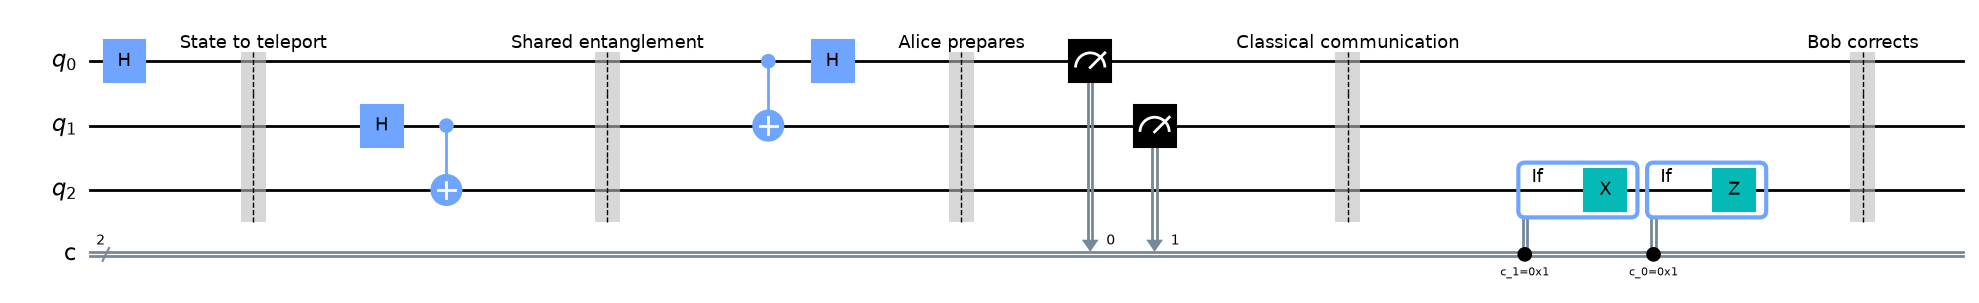

↑ the protocol left to right: prepare |+⟩ on q0, Bell pair on q1 q2, Alice's CNOT + H, her two measurements, then Bob's X and Z inside the if_test boxes controlled by the classical bits


In [2]:
# Create registers
q = QuantumRegister(3, 'q')  # 0: Alice's message, 1: Alice's EPR, 2: Bob's EPR
c = ClassicalRegister(2, 'c')  # Classical communication: the 2 bits Alice sends to Bob
qc = QuantumCircuit(q, c)    # a circuit built from registers (several classical registers are allowed)

# STEP 1: Prepare state to teleport |ψ⟩ = α|0⟩ + β|1⟩
# Example: |+⟩ state
qc.h(0)                                        # |ψ> = |+> = (|0> + |1>)/sqrt2 on the message qubit
qc.barrier(label='State to teleport')          # barriers only separate the steps visually (and stop the transpiler from merging across them)

# STEP 2: Create Bell pair between Alice (q1) and Bob (q2)
qc.h(1)
qc.cx(1, 2)                                    # (|00> + |11>)/sqrt2 on q1 q2: the shared entanglement
qc.barrier(label='Shared entanglement')

# STEP 3: Alice's operations
qc.cx(0, 1)  # Entangle message with her EPR qubit
qc.h(0)       # Hadamard on message qubit       # CNOT + H = a Bell-basis measurement of q0 q1, once we read them out
qc.barrier(label='Alice prepares')

# STEP 4: Alice measures and sends classical bits
qc.measure(0, 0)  # Measure q0 → c0
qc.measure(1, 1)  # Measure q1 → c1
qc.barrier(label='Classical communication')

# STEP 5: Bob's correction using dynamic circuits (Qiskit 2.2)
# If c[1] == 1, apply X
with qc.if_test((c[1], 1)):                    # if_test((bit, value)): the gates in the block run only when the measured bit equals value
    qc.x(2)

# If c[0] == 1, apply Z
with qc.if_test((c[0], 1)):
    qc.z(2)

qc.barrier(label='Bob corrects')

print(f'Teleportation circuit (Qiskit 2.2)')
print(f'  Depth: {qc.depth()}')
print(f'  Gates: {qc.size()}')
print(f'  Uses dynamic circuits: Yes')
display(draw(qc)); print("↑ the protocol left to right: prepare |+⟩ on q0, Bell pair on q1 q2, Alice's CNOT + H, her two measurements, then Bob's X and Z inside the if_test boxes controlled by the classical bits")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QuantumCircuit(q, c)` | a circuit from named registers: `q[0]` message, `q[1]` Alice's half of the pair, `q[2]` Bob's half; `c` holds the two classical bits that travel over the classical channel |
| `qc.cx(0, 1); qc.h(0)` + two measurements | a **Bell measurement** of q0 q1: CNOT then H maps the four Bell states onto \|00⟩, \|01⟩, \|10⟩, \|11⟩, so reading the two bits tells which Bell state Alice found |
| `with qc.if_test((c[1], 1)): qc.x(2)` | a classically controlled gate (Qiskit 2: `if_test` replaces the removed `c_if`): X on Bob's qubit only in the shots where Alice's bit c1 was 1; the second block applies Z when c0 was 1. This requires *mid-circuit feed-forward* from the backend |
| `qc.barrier(label=...)` | purely visual separators that name the five steps in the drawing (and prevent the transpiler from merging gates across them) |
| `Depth: 8`, `Gates: 9` | the circuit is inherently sequential — the corrections cannot start before the measurement results exist |

</details>


<details open><summary><b>📐 Working it out</b></summary>

Let $|\psi\rangle=\alpha|0\rangle+\beta|1\rangle$ on $q_0$ and the Bell pair $(|00\rangle+|11\rangle)/\sqrt2$ on $q_1q_2$. Writing kets as $|q_0\,q_1\,q_2\rangle$ (reading order of the protocol), the three-qubit state is

$$\frac{1}{\sqrt2}\big(\alpha|000\rangle+\alpha|011\rangle+\beta|100\rangle+\beta|111\rangle\big).$$

`cx(0, 1)` flips $q_1$ where $q_0=1$, then `h(0)` maps $|0\rangle\to(|0\rangle+|1\rangle)/\sqrt2$, $|1\rangle\to(|0\rangle-|1\rangle)/\sqrt2$. Collecting the terms by Alice's two bits $q_0q_1$:

$$\frac12\Big[\,|00\rangle\,(\alpha|0\rangle+\beta|1\rangle)\;+\;|01\rangle\,(\alpha|1\rangle+\beta|0\rangle)\;+\;|10\rangle\,(\alpha|0\rangle-\beta|1\rangle)\;+\;|11\rangle\,(\alpha|1\rangle-\beta|0\rangle)\Big].$$

Each of the four outcomes has probability $1/4$ **whatever** $\alpha,\beta$ are (Alice learns nothing about $|\psi\rangle$), and Bob's qubit is $|\psi\rangle$ up to a known Pauli: $q_1=1\Rightarrow$ apply $X$, $q_0=1\Rightarrow$ apply $Z$ (for $|11\rangle$: $Z X(\alpha|1\rangle-\beta|0\rangle)=Z(\alpha|0\rangle-\beta|1\rangle)=\alpha|0\rangle+\beta|1\rangle$). This is exactly the code: `if_test((c[1], 1)): x(2)` and `if_test((c[0], 1)): z(2)`.

For $|\psi\rangle=|+\rangle$ ($\alpha=\beta=1/\sqrt2$) Bob ends in $|+\rangle$, so a Z-measurement of his qubit gives $|0\rangle$ and $|1\rangle$ with probability $1/2$ each — the **50 %** the verification cells look for.

</details>


## 🧪 Verification

### Method: Check final state
We'll verify Bob's qubit (q2) has the teleported state.

Verification circuit:


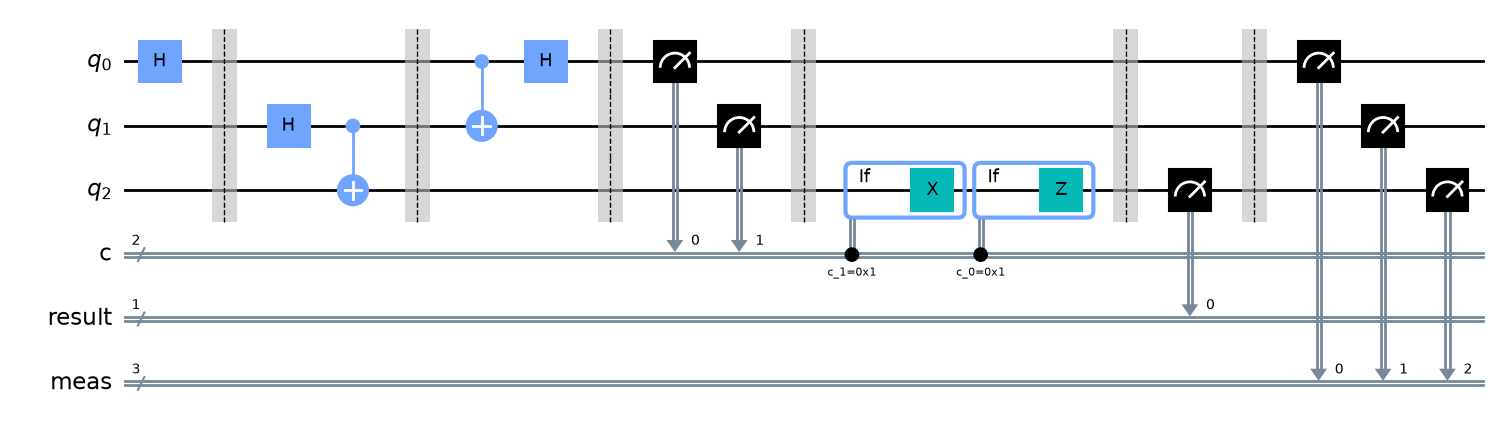

↑ the same protocol followed by a measurement of Bob's qubit into 'result' and a measure_all() into 'meas' (3 classical registers: c, result, meas)


In [3]:
# For verification, add measurement of Bob's qubit
c_verify = ClassicalRegister(1, 'result')      # a third classical register for Bob's bit
qc_verify = QuantumCircuit(q, c, c_verify)     # same qubits q and Alice's bits c, plus 'result'

# Rebuild circuit with verification
# STEP 1: Prepare state
qc_verify.h(0)                                 # |+> again
qc_verify.barrier()

# STEP 2: Bell pair
qc_verify.h(1)
qc_verify.cx(1, 2)
qc_verify.barrier()

# STEP 3: Alice's operations
qc_verify.cx(0, 1)
qc_verify.h(0)
qc_verify.barrier()

# STEP 4: Measurements
qc_verify.measure(0, 0)                        # q0 -> c[0]
qc_verify.measure(1, 1)                        # q1 -> c[1]
qc_verify.barrier()

# STEP 5: Bob's correction (dynamic circuits)
with qc_verify.if_test((c[1], 1)):             # X if Alice's second bit is 1
    qc_verify.x(2)
with qc_verify.if_test((c[0], 1)):             # Z if her first bit is 1
    qc_verify.z(2)

qc_verify.barrier()

# Measure Bob's qubit
qc_verify.measure(2, c_verify[0])              # Bob's bit -> register 'result'
qc_verify.measure_all()                        # adds a 3-bit register 'meas' and measures every qubit again (same values: already collapsed)
print('Verification circuit:')
display(draw(qc_verify)); print("↑ the same protocol followed by a measurement of Bob's qubit into 'result' and a measure_all() into 'meas' (3 classical registers: c, result, meas)")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `c_verify = ClassicalRegister(1, 'result')` | a separate register for Bob's outcome, so that it is not mixed with the two bits of the classical channel |
| `qc_verify.measure(2, c_verify[0])` + `measure_all()` | Bob's qubit is measured twice: once into `result`, once more by `measure_all()` into a new 3-bit register `meas` (together with q0 and q1). The second measurement repeats the first: the state has already collapsed. The author's analysis reads the `meas` register |
| same `if_test` blocks | the corrections are identical to the Implementation cell; Aer executes dynamic circuits natively |

</details>


### Execute

In [4]:
simulator = AerSimulator()                      # ideal local simulator; Aer supports dynamic circuits (if_test)
sampler = SamplerV2()                           # Aer's Sampler primitive: bitstrings, one entry per classical register
pm = generate_preset_pass_manager(optimization_level=1, backend=simulator)

transpiled = pm.run(qc_verify)                  # ISA circuit for Aer (the control flow is kept)

job = sampler.run([transpiled], shots=1024)     # a list of pubs; 1024 repetitions of the whole protocol
result = job.result()

counts = result[0].data.meas.get_counts()       # the 'meas' register of measure_all(): keys 'q2 q1 q0' (data.c and data.result hold the other registers)
print(f'{sum(counts.values())} shots, {len(counts)} distinct outcomes of the meas register')

def run_circuit(circuit, shots=1024):
    """Transpile + run + counts of ALL classical registers in one call (used by the In-depth analysis)."""
    return simulator.run(pm.run(circuit), shots=shots).result().get_counts()


1024 shots, 8 distinct outcomes of the meas register


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `sampler.run([transpiled], shots=1024)` | the Sampler executes the dynamic circuit 1024 times; the `if_test` blocks are evaluated shot by shot on the measured bits |
| `result[0].data.meas.get_counts()` | SamplerV2 returns one container per classical register: `.meas` is the 3-bit register added by `measure_all()`, with keys `'q2 q1 q0'` (leftmost = Bob); `.c` and `.result` would give the other two |
| `run_circuit(circuit, shots)` | the same backend through `simulator.run(...)`: it returns the counts of *all* registers in one key (`'meas result c'`, space-separated), the format the In-depth analysis parses |
| 8 distinct outcomes | 2 bits of Alice × Bob's bit: every combination appears, each about 1/8 — the signature of teleporting \|+⟩ |

</details>


Results (leftmost bit = Bob's qubit q2, from the measure_all() register):
Expected: Bob's qubit in |+⟩ state → 50% |0⟩, 50% |1⟩

Bob received |0⟩: 501 times (48.9%)
Bob received |1⟩: 523 times (51.1%)

Top measurement outcomes:
  000: 141
  101: 139
  110: 130
  100: 128
  010: 128


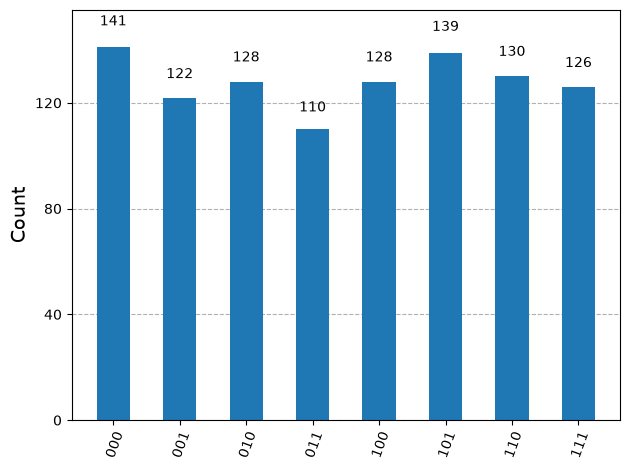

In [5]:
print("Results (leftmost bit = Bob's qubit q2, from the measure_all() register):")
print('Expected: Bob\'s qubit in |+⟩ state → 50% |0⟩, 50% |1⟩')
print()

# Analyze results
bob_0_count = 0
bob_1_count = 0

for bitstring, count in counts.items():
    # The key starts with the 'meas' register 'q2 q1 q0' (Aer: only that register; IQM: 'q2q1q0 result c1c0'):
    # the leftmost character is Bob's qubit in both cases
    if len(bitstring) >= 3:
        bob_result = bitstring[0]  # Leftmost bit
        if bob_result == '0':
            bob_0_count += count
        else:
            bob_1_count += count

print(f'Bob received |0⟩: {bob_0_count} times ({bob_0_count/1024:.1%})')   # :.1% formats a fraction as a percentage with one decimal
print(f'Bob received |1⟩: {bob_1_count} times ({bob_1_count/1024:.1%})')
print()
print('Top measurement outcomes:')
for state, count in sorted(counts.items(), key=lambda x: -x[1])[:5]:   # sort by count, descending; keep the first five
    print(f'  {state}: {count}')

plot_histogram(counts)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `bitstring[0]` | Qiskit prints classical bits from the highest index down, so the leftmost character of the `meas` group is q2 = Bob's qubit; the two characters after it are Alice's q1 q0 |
| `bob_0_count / 1024` | about 50 % each: the teleported state is \|+⟩, whose Z-measurement is a fair coin. The *proof* that teleportation worked is not this 50/50 (a random qubit would give the same) but the fact that it holds for every value of Alice's bits — see the In-depth analysis for a test that catches phase errors |
| `sorted(counts.items(), key=lambda x: -x[1])[:5]` | a lambda picks the count as sorting key; the minus sign sorts descending; the slice keeps the five most frequent outcomes |
| `plot_histogram(counts)` | all combinations of (Bob, Alice's two bits) appear with similar heights: the four Bell outcomes are equally likely and Bob's bit is independent of them |

</details>


## 📊 Analysis

### Expected Results
Since we teleported |+⟩ = (|0⟩ + |1⟩)/√2:  
Bob's measurement should give **50% |0⟩, 50% |1⟩**

### Classical Communication
Alice sends 2 bits (4 possibilities):
- 00, 01, 10, 11 equally likely (25% each)

### Key Points:
1. **No-cloning theorem**: Original state destroyed (measured)
2. **Classical bits required**: Can't teleport faster than light!
3. **Perfect fidelity**: Exact state transfer (in ideal case)
4. **Entanglement consumed**: Bell pair used up
5. **Dynamic circuits**: Modern Qiskit 2.2 uses `if_test` for conditionals

## 💡 Alternative: Teleport Different States

Teleporting |1⟩ state:
  Bob got |1⟩: 1024 times (100.0%)

✓ Should be 100% |1⟩!


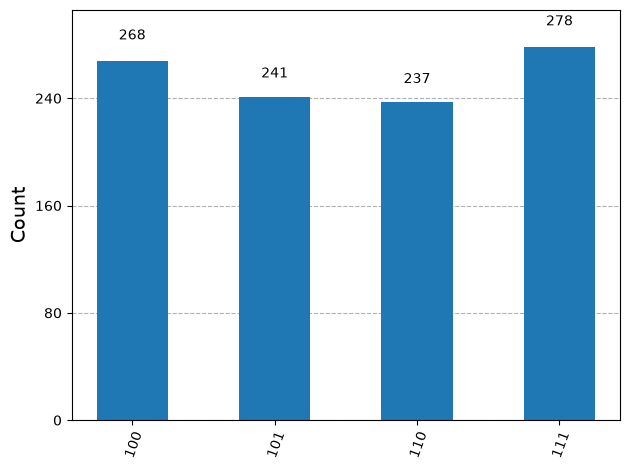

In [6]:
def teleport_state(state_prep_func, n_shots=1024):
    """
    Teleport arbitrary single-qubit state.

    Args:
        state_prep_func: Function that prepares state on qubit 0
        n_shots: Number of measurements

    Returns:
        Measurement counts
    """
    q = QuantumRegister(3, 'q')
    c = ClassicalRegister(2, 'c')
    c_result = ClassicalRegister(1, 'result')
    qc = QuantumCircuit(q, c, c_result)

    # Prepare state to teleport
    state_prep_func(qc, 0)                     # the caller decides which state: any function (circuit, qubit) -> gates
    qc.barrier()

    # Bell pair
    qc.h(1)
    qc.cx(1, 2)
    qc.barrier()

    # Alice's operations
    qc.cx(0, 1)
    qc.h(0)
    qc.barrier()

    # Measure Alice's qubits
    qc.measure(0, 0)
    qc.measure(1, 1)
    qc.barrier()

    # Bob's correction
    with qc.if_test((c[1], 1)):
        qc.x(2)
    with qc.if_test((c[0], 1)):
        qc.z(2)
    qc.barrier()

    # Measure Bob's qubit
    qc.measure(2, c_result[0])
    qc.measure_all()

    # Execute
    simulator = AerSimulator()
    sampler = SamplerV2()
    pm = generate_preset_pass_manager(optimization_level=1, backend=simulator)
    transpiled = pm.run(qc)

    job = sampler.run([transpiled], shots=n_shots)
    result = job.result()
    return result[0].data.meas.get_counts()    # the 3-bit 'meas' register: leftmost bit = Bob

# Example: Teleport |1⟩ state
def prepare_one(qc, qubit):
    qc.x(qubit)                                # |1> = X|0>

counts_one = teleport_state(prepare_one)
print('Teleporting |1⟩ state:')

# Count Bob's results
bob_results = {}
for bitstring, count in counts_one.items():
    bob_bit = bitstring[0]                     # leftmost character = Bob's qubit
    bob_results[bob_bit] = bob_results.get(bob_bit, 0) + count   # dict.get(key, 0): start from 0 the first time a key is seen

for bit, count in sorted(bob_results.items()):
    print(f'  Bob got |{bit}⟩: {count} times ({count/1024:.1%})')

print('\n✓ Should be 100% |1⟩!')
plot_histogram(counts_one)                     # the histogram of THIS run (the original plotted the previous `counts` by mistake)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `def teleport_state(state_prep_func, n_shots)` | the whole protocol as a function whose first argument is *another function*: `state_prep_func(qc, 0)` writes the state to teleport, so the same code tests \|1⟩, \|+⟩ or any rotation |
| `bob_results.get(bob_bit, 0) + count` | the idiom for counting into a dictionary without initialising every key first |
| `100 % \|1⟩` | for \|ψ⟩ = \|1⟩ a Z-measurement of Bob is deterministic, so this run is a sharper test than the \|+⟩ run — and a correction that was skipped would show up at once as 50 % |
| `plot_histogram(counts_one)` | the four Alice outcomes `q1 q0` appear with Bob's bit always 1: keys `100`, `101`, `110`, `111` only |

</details>


## 🎯 Applications

1. **Quantum Networks**: Distribute quantum information
2. **Quantum Cryptography**: Secure key distribution (QKD)
3. **Distributed Computing**: Link quantum processors
4. **Quantum Internet**: Future communication infrastructure
5. **Quantum Repeaters**: Extend quantum communication range

## 🎓 Exercises

### Exercise 1: Different State (Easy)
Teleport |1⟩ instead of |+⟩. Verify Bob receives |1⟩ with 100% probability.

**Hint**: Use `qc.x(0)` to prepare |1⟩

### Exercise 2: Arbitrary State (Medium)
Teleport state |ψ⟩ = cos(θ)|0⟩ + sin(θ)|1⟩ for θ=π/3.

**Hint**: Use `qc.ry(2*θ, 0)` to prepare this state

### Exercise 3: Entanglement Swapping (Hard)
Extend to 4 qubits: Create Bell pair on qubits 0-1, teleport qubit 0 to qubit 3. Result: qubits 1-3 should be entangled!

## 🔬 Technical Notes

### Qiskit 2.2 Changes
- **Removed**: `c_if()` method for classical conditionals
- **New**: Dynamic circuits with `if_test` context manager
- **Benefit**: More flexible classical control flow
- **Requirement**: Backend must support dynamic circuits

### Circuit Depth
Teleportation is inherently **sequential**:
1. Bell pair creation
2. Alice's operations
3. Alice's measurements
4. Bob's corrections

Cannot be parallelized due to classical communication step.

## 🔬 In-depth analysis

The verification above only checks the probabilities of Bob's bit. A sharper test, and one that runs on any backend (no `if_test`): build the protocol with Bob's corrections as a CNOT and a CZ *before* Alice's measurement (**deferred measurement**), with one 3-bit classical register (bits 0, 1 = Alice, bit 2 = Bob), and use the `run_circuit(circuit, shots)` helper defined in the Execute cell.

1. Teleport \|ψ⟩ = cos(π/3)\|0⟩ + sin(π/3)\|1⟩ (prepared by `ry(2π/3, 0)`, the author's Exercise 2) and check that Bob's P(1) ≈ sin²(π/3) = 0.75.
2. Remove Bob's corrections and repeat: what does Bob's P(1) become, and why?
3. Test the *whole* state, phases included: apply the inverse preparation `ry(−2π/3)` to Bob's qubit before measuring it. If teleportation worked, Bob's qubit is back in \|0⟩ with probability 1.

Write your code in the empty cell below; a reference solution follows it. Try first, then compare.


In [7]:
# 🔬 In-depth analysis — your code here



(1) Bob P(1) with corrections     = 0.749   (expected sin²(π/3) = 0.750)
(2) Bob P(1) without corrections  = 0.502   (expected 0.5: in half of the shots Bob holds X|ψ>, whose P(1) is cos²(π/3) = 0.25)
(3) Bob P(0) after undoing the preparation = 1.000   (expected 1.0: the full state arrived, phases included)


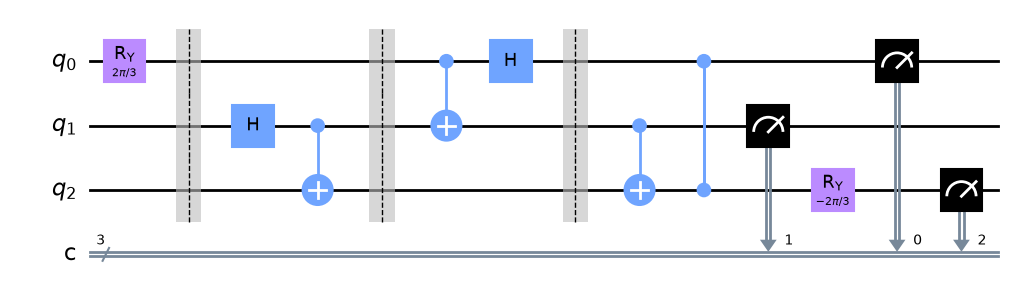

↑ task 3: Ry(2π/3) on q0, Bell pair, Alice's CNOT + H, the deferred corrections CNOT(1→2) and CZ(0→2), Ry(−2π/3) on Bob, then the three measurements


In [8]:
# Reference solution
def teleport_deferred(prep, correct=True, undo=None):
    """Teleportation of the state prep(qc, 0) with Bob's corrections as CNOT/CZ (deferred measurement), runnable on any backend.
    undo(qc, 2), if given, is applied to Bob's qubit before its measurement (the inverse preparation -> expect |0>)."""
    qc = QuantumCircuit(3, 3)                  # one classical register: bits 0, 1 = Alice, bit 2 = Bob -> keys 'bob a1 a0'
    prep(qc, 0); qc.barrier()                  # the state to teleport
    qc.h(1); qc.cx(1, 2); qc.barrier()         # Bell pair
    qc.cx(0, 1); qc.h(0); qc.barrier()         # Alice's Bell-basis rotation
    if correct:
        qc.cx(1, 2)                            # X^{a1}: X on Bob controlled by q1
        qc.cz(0, 2)                            # Z^{a0}: Z on Bob controlled by q0
    if undo:
        undo(qc, 2)                            # optional inverse preparation on Bob
    qc.measure([0, 1, 2], [0, 1, 2])           # Alice's bits and Bob's bit
    return qc

def bob_p1(counts):
    """Probability that Bob's bit (classical bit 2 = leftmost character) is 1."""
    total = sum(counts.values())
    return sum(n for bits, n in counts.items() if bits[0] == '1') / total

theta = np.pi / 3
prep = lambda qc, q: qc.ry(2 * theta, q)       # cos(θ)|0> + sin(θ)|1>   (Ry(2θ) rotates by θ on the Bloch sphere's half-angle convention)
undo = lambda qc, q: qc.ry(-2 * theta, q)      # the inverse rotation

p1 = bob_p1(run_circuit(teleport_deferred(prep), 2048))
p1_nocorr = bob_p1(run_circuit(teleport_deferred(prep, correct=False), 2048))
p1_undo = bob_p1(run_circuit(teleport_deferred(prep, undo=undo), 2048))
print(f'(1) Bob P(1) with corrections     = {p1:.3f}   (expected sin²(π/3) = {np.sin(theta)**2:.3f})')
print(f'(2) Bob P(1) without corrections  = {p1_nocorr:.3f}   (expected 0.5: in half of the shots Bob holds X|ψ>, whose P(1) is cos²(π/3) = 0.25)')
print(f'(3) Bob P(0) after undoing the preparation = {1 - p1_undo:.3f}   (expected 1.0: the full state arrived, phases included)')
display(draw(teleport_deferred(prep, undo=undo))); print("↑ task 3: Ry(2π/3) on q0, Bell pair, Alice's CNOT + H, the deferred corrections CNOT(1→2) and CZ(0→2), Ry(−2π/3) on Bob, then the three measurements")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `teleport_deferred(prep, correct, undo)` | one builder for the three tasks: `prep` and `undo` are small functions (here lambdas) that add gates to a given qubit; `correct=False` switches the corrections off; `QuantumCircuit(3, 3)` keeps the keys simple (`'bob a1 a0'`) |
| `qc.cx(1, 2); qc.cz(0, 2)` | deferred measurement: a Pauli applied *if* a bit is 1 equals the same Pauli controlled by the qubit before it is measured — the circuit then has no classical control and runs on every backend, IQM included |
| `bits[0] == '1'` | Qiskit prints classical bit 2 first, so the leftmost character is Bob's result |
| `(2)` = 0.5 | without corrections Bob holds \|ψ⟩, X\|ψ⟩, Z\|ψ⟩ or XZ\|ψ⟩ with probability 1/4 each; the Z's do not change P(1), the X's swap it with P(0): (0.75 + 0.25 + 0.75 + 0.25)/4 = 0.5 — a maximally mixed qubit, which is exactly what Bob has *before* receiving Alice's two bits (no faster-than-light signalling) |
| `(3)` ≈ 1 | the inverse rotation maps \|ψ⟩ back to \|0⟩ only if the amplitudes *and* their relative phase are right: a missed Z correction would give 0.25 here while leaving task 1 unchanged. On a noisy backend the deficit from 1 is the infidelity of the whole protocol |

</details>


<details open><summary><b>📐 Working it out</b></summary>

$R_y(2\theta)|0\rangle=\cos\theta\,|0\rangle+\sin\theta\,|1\rangle$; with $\theta=\pi/3$:

$$P(1)=\sin^2\frac{\pi}{3}=\Big(\frac{\sqrt3}{2}\Big)^2=\frac34=0.75,\qquad P(0)=\cos^2\frac{\pi}{3}=\frac14 .$$

Without corrections (task 2) the four Bell outcomes leave Bob with $|\psi\rangle,\ X|\psi\rangle,\ Z|\psi\rangle,\ XZ|\psi\rangle$, each with probability $1/4$ (box above). $Z$ changes only the sign of the $|1\rangle$ amplitude, $X$ swaps the two amplitudes, so

$$P(1)=\tfrac14\,(0.75+0.25+0.75+0.25)=0.5 .$$

With corrections and the inverse rotation (task 3), $R_y(-2\theta)R_y(2\theta)|0\rangle=|0\rangle$: $P(0)=1$ ideally; shot noise (2048 shots) and, on a noisy backend, gate errors account for the deficit printed.

</details>


## 📖 References

1. **Bennett et al. (1993)**. *Teleporting an unknown quantum state via dual classical and Einstein-Podolsky-Rosen channels*. Physical Review Letters.

2. **Nielsen & Chuang**. *Quantum Computation and Quantum Information*, Chapter 1.3.7

3. **Qiskit Documentation**: Dynamic Circuits  
   https://docs.quantum.ibm.com/guides/dynamic-circuits

4. **Qiskit Textbook**: Quantum Teleportation  
   https://learn.qiskit.org

---

**Version**: 2.2.0 (Corrected)  
**License**: MIT  
**Last Updated**: November 2025

**Note**: This version uses proper Qiskit 2.2 dynamic circuits syntax.